# 2.20 · Tempering and SMC: turning the data up slowly

**Before this:** [2.16](2-16_metropolis.ipynb) (Metropolis), [2.19](2-19_convergence_rhat.ipynb) (R-hat, multiple modes).
**You will be able to:** explain tempering and why it lets a population reach separated modes; run the three steps
of an SMC stage (reweight, resample, move); choose the tempering steps adaptively; recognise particle degeneracy;
read the evidence that SMC produces as a by-product; say what tempering does and does not address.
**Optional sections:** 9 (evidence).

A Metropolis or NUTS chain explores by moving through the parameter space. If the posterior has two islands
separated by a sea of near-zero probability, the chain stays on the island where it started (notebook 2.19).
**Tempering** removes the sea temporarily: start from the prior, where everything is connected, and let the data
in a little at a time. **Sequential Monte Carlo (SMC)** is the sampler built on that idea. It moves a whole
population of particles through the sequence. CATMIP and AlTar are SMC samplers of exactly this kind.

**Words this notebook defines:** tempering (β), annealing, importance weights, resampling, effective sample
size (ESS) of the weights, particle degeneracy, move (mutation) step, adaptive schedule (the COV rule),
evidence.

**Problems in this notebook** (size and forward model; notebook 2.25 explains the degree of nonlinearity)

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| sign ambiguity (1) | 1 | 1 | $d = m^2$ | nonlinear |
| two modes | 2 | 2 | distances to two stations | nonlinear |
| trade-off and banana (7) | 2 | 2 / 1 | $\mathbf G\mathbf m$ / distance | linear / nonlinear |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import inspect
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import jax.numpy as jnp
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S

np.seterr(over="ignore")                     # exp overflow inside min(1, exp(.)) is harmless
SMC_C = S.COLORS["smc"]
bim = P.location(kind="bimodal")             # the two-station epicentre problem from notebook 2.02
g_bim = P.grid(bim, n=500)
north_true = g_bim.mass(lambda X, Y: Y > 0)
print("exact probability of the northern mode (grid): %.3f" % north_true)

exact probability of the northern mode (grid): 0.686


## 1. Tempering: the likelihood raised to a power β between 0 and 1

$$p_\beta(\mathbf m) \;\propto\; p(\mathbf m)\, L(\mathbf m)^{\beta}, \qquad 0 \le \beta \le 1 .$$

At $\beta = 0$ this is the prior; at $\beta = 1$ it is the posterior. In between, the data count with a reduced
weight, as if every noise $\sigma$ were inflated to $\sigma/\sqrt{\beta}$. The word comes from metallurgy (anneal
slowly so the metal settles into a good state): $1/\beta$ is called the *temperature*. Hot means flat.

First a 1-D example: the datum is $d = m^2$, so the data cannot tell the sign of $m$ (two peaks at $\pm 2$),
and the prior leans slightly positive.

saved figures/2-20_tempering_1d.png


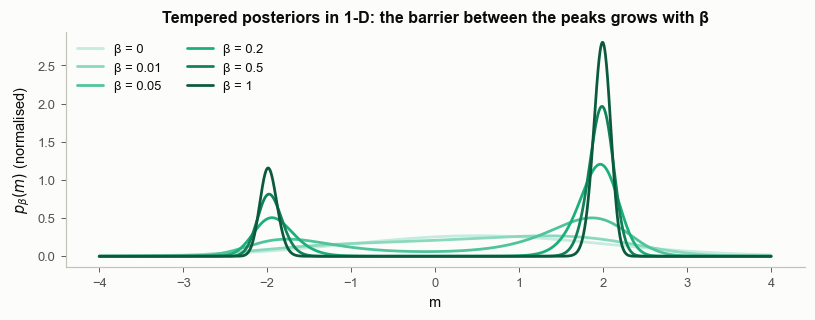

beta  0.00: density at m = 0 relative to the higher peak = 9.46e-01
beta  0.01: density at m = 0 relative to the higher peak = 7.81e-01
beta  0.05: density at m = 0 relative to the higher peak = 1.23e-01
beta  0.20: density at m = 0 relative to the higher peak = 7.00e-05
beta  0.50: density at m = 0 relative to the higher peak = 2.16e-11
beta  1.00: density at m = 0 relative to the higher peak = 3.00e-22


In [2]:
betas_show = [0.0, 0.01, 0.05, 0.2, 0.5, 1.0]
ramp = ["#c4ece0", "#8ad8be", "#4fc39c", "#1baf7a", "#11815a", "#0b5a3f"]   # one hue (aqua), light = hot
m = np.linspace(-4, 4, 2001)
log_prior_1d = -0.5 * ((m - 0.5) / 1.5) ** 2
log_lik_1d = -0.5 * ((4.0 - m ** 2) / 0.4) ** 2
fig, ax = plt.subplots(figsize=(7.5, 3.0))
for b, col in zip(betas_show, ramp):
    lp = log_prior_1d + b * log_lik_1d
    p = np.exp(lp - lp.max())
    p /= np.trapezoid(p, m)
    ax.plot(m, p, color=col, lw=1.8, label=f"β = {b:g}")
ax.set_xlabel("m")
ax.set_ylabel("$p_\\beta(m)$ (normalised)")
ax.set_title("Tempered posteriors in 1-D: the barrier between the peaks grows with β")
ax.legend(ncol=2, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-20_tempering_1d")
plt.show()
mid = np.argmin(np.abs(m))
for b in betas_show:
    lp = log_prior_1d + b * log_lik_1d
    print("beta %5.2f: density at m = 0 relative to the higher peak = %.2e" % (b, np.exp(lp[mid] - lp.max())))

The same in 2-D, on the two-station epicentre problem (two islands, notebook 2.02):

saved figures/2-20_tempering_2d.png


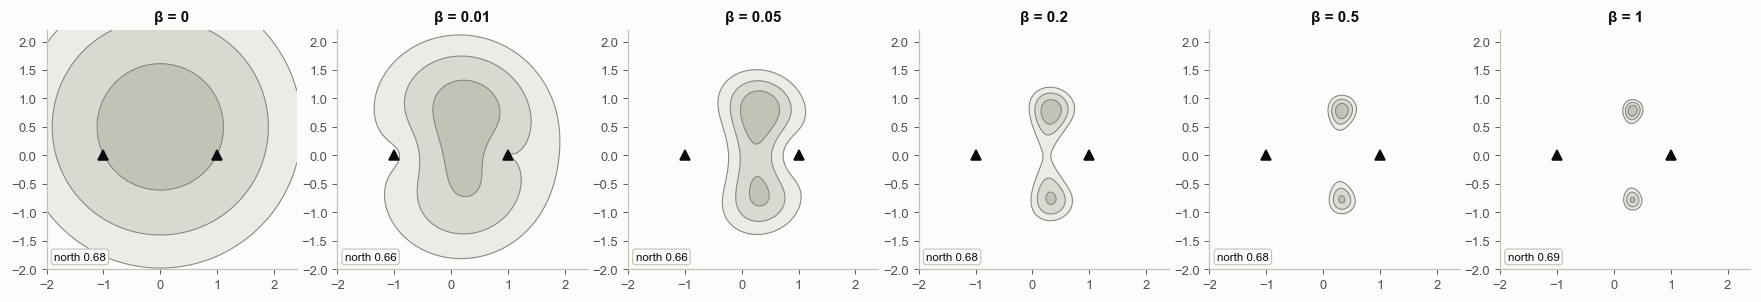

In [3]:
def tempered(prob, beta):
    """p_beta = prior x L^beta as a bayeskit Target (JAX log density, so it also has a gradient)."""
    t = P.Target(lambda z: prob.logprior_fn(z) + beta * prob.loglik_fn(z), prob.dim, f"beta = {beta:g}",
                 extent=prob.extent, labels=prob.labels)
    return t


fig, axs = plt.subplots(1, 6, figsize=(16, 2.95))
for ax, b in zip(axs, betas_show):
    gt = P.grid(tempered(bim, b), n=300)
    BP.density(ax, gt)
    ax.plot([-1, 1], [0, 0], "^", color=S.INK, ms=6)
    BP.frame(ax, bim, equal=True, labels=False)
    ax.set_title(f"β = {b:g}", fontsize=10)
    S.badge(ax, "north %.2f" % gt.mass(lambda X, Y: Y > 0), loc="lower left", fs=7.5)
fig.tight_layout()
bk.savefig(fig, "2-20_tempering_2d")
plt.show()

**The image to keep:** at small β the posterior is one broad, connected blob (the prior, slightly tilted by the
data). As β grows, two islands condense out of it and the sea between them deepens. The badges give the share of
probability in the north at each β; in this problem it hardly changes (the prior already leans north), in others
it does. What SMC needs is particles on *both* islands before the islands separate. After that, reweighting can
still shift probability between the islands, but no move can carry a particle across.

## 2. Why it helps: the barrier height is proportional to β

Same Metropolis sampler, same step size (0.2), run on $p_\beta$ for several β. We count how often the chain
switches between north and south in 5000 steps.

saved figures/2-20_why_tempering_helps.png


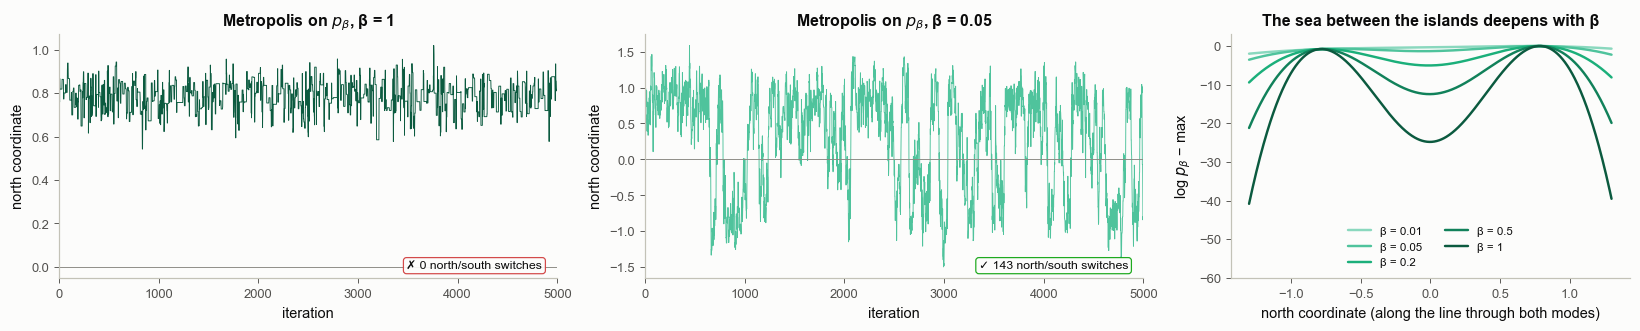

 beta  acceptance  switches  fraction north
 1.00        0.14         0            1.00
 0.20        0.41         2            0.91
 0.05        0.67       143            0.68
 0.01        0.82       183            0.71
exact north fraction at beta = 1: 0.686


In [4]:
step = 0.2
fig, axs = plt.subplots(1, 3, figsize=(15, 3.1), gridspec_kw=dict(width_ratios=[1.25, 1.25, 1]))
rows = []
for b, col in [(1.0, ramp[-1]), (0.05, ramp[2])]:
    r = SM.rwm(tempered(bim, b), np.array([[0.3, 0.8]]), 5000, step=step, rng=np.random.default_rng(3))
    y = r["chain"][:, 1]
    ax = axs[0] if b == 1.0 else axs[1]
    BP.trace(ax, y, color=col, lw=0.6)
    ax.axhline(0, color=S.MUTED, lw=0.6)
    ax.set_title(f"Metropolis on $p_\\beta$, β = {b:g}")
    ax.set_xlabel("iteration")
    ax.set_ylabel("north coordinate")
for b in [1.0, 0.2, 0.05, 0.01]:
    r = SM.rwm(tempered(bim, b), np.array([[0.3, 0.8]]), 5000, step=step, rng=np.random.default_rng(3))
    y = r["chain"][:, 1]
    rows.append((b, r["accept_rate"], int(np.sum(np.diff(np.sign(y)) != 0)), np.mean(y > 0)))
for ax, (b, acc, sw, nf) in zip(axs[:2], [rows[0], rows[2]]):
    S.badge(ax, f"{sw} north/south switches", ok=sw > 0, loc="lower right", fs=8)
# log p_beta along the north-south line through both modes
x_line = g_bim.X[0][np.argmax(g_bim.P.max(0))]
yl = np.linspace(-1.3, 1.3, 600)
pts = np.column_stack([np.full_like(yl, x_line), yl])
lpri, llik = bim.logprior_batch(pts), bim.loglik_batch(pts)
for b, col in zip(betas_show[1:], ramp[1:]):
    v = lpri + b * llik
    axs[2].plot(yl, v - v.max(), color=col, lw=1.6, label=f"β = {b:g}")
axs[2].set_ylim(-60, 3)
axs[2].set_xlabel("north coordinate (along the line through both modes)")
axs[2].set_ylabel("log $p_\\beta$ − max")
axs[2].set_title("The sea between the islands deepens with β")
axs[2].legend(fontsize=7.5, ncol=2, loc="lower center")
fig.tight_layout()
bk.savefig(fig, "2-20_why_tempering_helps")
plt.show()
print(" beta  acceptance  switches  fraction north")
for b, acc, sw, nf in rows:
    print(f"{b:5.2f}  {acc:10.2f}  {sw:8d}  {nf:14.2f}")
print("exact north fraction at beta = 1: %.3f" % north_true)

The log density along the line through both modes is $\log p(\mathbf m) + \beta \log L(\mathbf m)$, so the depth of the
valley between the islands scales with β. A Metropolis step must climb out of the valley to cross, and the
chance of accepting such a step is roughly $e^{-\text{depth}}$. At β = 1 the chain never crosses, so it reports
the northern island as certain: a confident wrong answer. At β = 0.05 the same chain crosses freely and its north fraction is close
to the exact value for that tempered posterior (badge in the β = 0.05 panel above). (A huge step can occasionally *jump* the valley at
β = 1, at the price of rejecting almost every proposal; it is a lottery, not a method.)

## 3. One SMC stage, step by step

SMC carries $N$ particles from $\beta = 0$ (prior draws) to $\beta = 1$ (posterior). Each stage does three things:

1. **Reweight.** Going from $\beta$ to $\beta' = \beta + \Delta\beta$, each particle gets an **importance weight**
   $w_i = L(\mathbf m_i)^{\Delta\beta}$: particles that fit the data better count more. (An importance weight corrects
   for particles drawn from one distribution, here $p_\beta$, being used to represent another, $p_{\beta'}$: each
   counts in proportion to the ratio of the two densities at its position.) The next β is chosen so the weights are
   not too uneven (section 5).
2. **Resample.** Draw $N$ new particles from the old ones with probability proportional to $w_i$. Heavy particles are
   copied, light ones die. Now all weights are equal again.
3. **Move.** Copies sit on top of each other, so every particle takes a few Metropolis steps targeting $p_{\beta'}$.
   The proposal covariance is the (weighted) covariance of the particle cloud, scaled by $c$ (in CATMIP,
   $c = a + bR$ with $a = 1/9$, $b = 8/9$ and $R$ the acceptance rate of the previous stage's moves, so the steps
   shrink when too few moves are accepted; Minson et al. 2013).

Here is the code that runs below (bayeskit's version of the CATMIP algorithm):

In [5]:
print(inspect.getsource(SM.smc))

def smc(problem, n=2000, rng=None, n_mcmc=10, cov_target=1.0, betas=None, scale0=0.5, record=True):
    """Sequential Monte Carlo with likelihood tempering, in the style of CATMIP (Minson et al. 2013).

    Targets p_beta(m) ~ p(m) L(m)^beta for beta going 0 -> 1. Each stage:
      1. choose the next beta so that the importance weights w = L^dbeta have coefficient of variation
         cov_target (=1 means effective sample size N/2), unless a fixed schedule `betas` is given;
      2. weight and resample the particles;
      3. move every particle with n_mcmc Metropolis steps whose proposal covariance is the particle
         covariance times c^2, with c = 1/9 + 8/9 * (last acceptance rate)  (the a + bR rule).
    Returns the stages (particles, beta, ESS, acceptance) and the log evidence estimate.
    """
    rng = rng or np.random.default_rng()
    X = problem.sample_prior(rng, n)
    d = X.shape[1]
    ll = problem.loglik_batch(X)
    lpri = problem.logprior_batch(X)
    beta, logZ, c

To draw the intermediate steps, the next cell repeats exactly the same algebra while keeping the weights and the
particles before and after each move. It is checked against `SM.smc`: with the same seed it must return
identical particles.

identical to bayeskit.samplers.smc with the same seed: True


saved figures/2-20_smc_one_stage.png


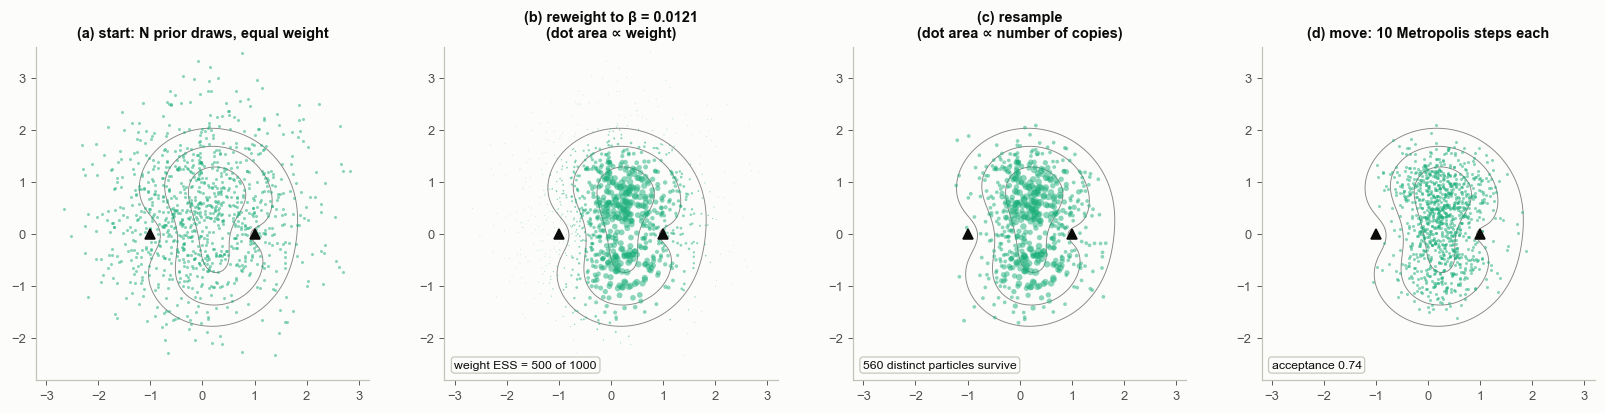

In [6]:
def smc_steps(problem, n, rng, n_mcmc=10, cov_target=1.0, betas=None, scale0=0.5):
    """Same algorithm and random-number order as bayeskit.samplers.smc, but records every sub-step."""
    X = problem.sample_prior(rng, n)
    d = X.shape[1]
    ll, lpri = problem.loglik_batch(X), problem.logprior_batch(X)
    beta, c, rec = 0.0, scale0, []
    sched = list(betas) if betas is not None else None
    while beta < 1.0 - 1e-12:
        llc = ll - ll.max()
        cov_w = lambda db: np.exp(db * llc).std() / np.exp(db * llc).mean()
        if sched is not None:
            db = max(min(sched.pop(0) if sched else 1.0, 1.0) - beta, 0.0)
        elif cov_w(1.0 - beta) <= cov_target:
            db = 1.0 - beta
        else:
            lo, hi = 0.0, 1.0 - beta
            for _ in range(60):
                mid = 0.5 * (lo + hi)
                lo, hi = (mid, hi) if cov_w(mid) < cov_target else (lo, mid)
            db = lo if lo > 0 else hi
        w = np.exp(db * llc)
        wn = w / w.sum()
        mean = wn @ X
        Cw = (X - mean).T @ ((X - mean) * wn[:, None])
        idx = SM.systematic_resample(wn, rng)
        st = dict(beta_from=beta, X_before=X.copy(), w=wn, ess=1.0 / np.sum(wn ** 2), idx=idx, c=c)
        X, ll, lpri = X[idx], ll[idx], lpri[idx]
        st["X_resampled"] = X.copy()
        beta = min(beta + db, 1.0)
        Lc = np.linalg.cholesky(Cw + 1e-12 * np.eye(d))
        acc_sum = 0.0
        for _ in range(n_mcmc):
            Y = X + c * rng.standard_normal((n, d)) @ Lc.T
            llY, lpY = problem.loglik_batch(Y), problem.logprior_batch(Y)
            ok = np.log(rng.uniform(size=n)) < (lpY + beta * llY) - (lpri + beta * ll)
            X[ok], ll[ok], lpri[ok] = Y[ok], llY[ok], lpY[ok]
            acc_sum += ok.mean()
        acc = acc_sum / n_mcmc
        c = 1.0 / 9.0 + 8.0 / 9.0 * acc
        st.update(beta=beta, X_moved=X.copy(), accept=acc)
        rec.append(st)
    return rec


N = 1000
EXT = (-3.2, 3.2, -2.8, 3.6)                     # map window used for the SMC pictures
steps = smc_steps(bim, N, np.random.default_rng(7))
ref = SM.smc(bim, n=N, rng=np.random.default_rng(7))
print("identical to bayeskit.samplers.smc with the same seed:", np.allclose(steps[-1]["X_moved"], ref["samples"]))

st = steps[0]
counts = np.bincount(st["idx"], minlength=N)
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
titles = ["(a) start: N prior draws, equal weight",
          f"(b) reweight to β = {st['beta']:.4f}\n(dot area ∝ weight)",
          "(c) resample\n(dot area ∝ number of copies)",
          f"(d) move: {10} Metropolis steps each"]
gt = P.grid(tempered(bim, st["beta"]), extent=EXT, n=300)
for ax, t in zip(axs, titles):
    BP.density(ax, gt, fill=False, lw=0.6)
    ax.set_title(t, fontsize=9.5)
axs[0].scatter(*st["X_before"].T, s=4, color=SMC_C, alpha=0.5, lw=0)
axs[1].scatter(*st["X_before"].T, s=np.clip(st["w"] * N * 6, 0.2, 200), color=SMC_C, alpha=0.5, lw=0)
uniq = counts > 0
axs[2].scatter(*st["X_before"][uniq].T, s=counts[uniq] * 6, color=SMC_C, alpha=0.5, lw=0)
axs[3].scatter(*st["X_moved"].T, s=4, color=SMC_C, alpha=0.5, lw=0)
for ax in axs:
    ax.plot([-1, 1], [0, 0], "^", color=S.INK, ms=6)
    ax.set_xlim(-3.2, 3.2); ax.set_ylim(-2.8, 3.6); ax.set_aspect("equal")
S.badge(axs[1], "weight ESS = %.0f of %d" % (st["ess"], N), loc="lower left", fs=8)
S.badge(axs[2], "%d distinct particles survive" % uniq.sum(), loc="lower left", fs=8)
S.badge(axs[3], "acceptance %.2f" % st["accept"], loc="lower left", fs=8)
fig.tight_layout()
bk.savefig(fig, "2-20_smc_one_stage")
plt.show()

Grey contours: the tempered target $p_{\beta'}$ of this stage. Reweighting (b) already describes $p_{\beta'}$, but
only through uneven weights on the old positions. Resampling (c) turns weights into copies, and the move step (d)
spreads the copies out so that the next stage again has $N$ distinct particles. The moves use the particle
covariance as their shape, which is why they work on ridges too.

## 4. A whole SMC run

The animation plays every stage of the run above. The grey background is the tempered posterior for the current β,
so you can watch it sharpen into two islands while the particles follow: 1 reweight (dot size = weight),
2 resample (particles that fit badly fade out, good ones are cloned), 3 move (each clone slides off its parent
with Metropolis steps). The bar at the bottom right shows β on a log scale. The static figure
after it shows the particles after each stage on top of the exact tempered posterior for that β.

GIF size 2.3 MB



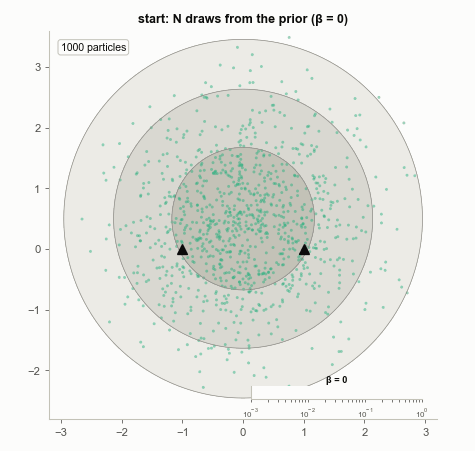

saved figures/2-20_smc_bimodal_final.png
The last frame at full resolution (300 dpi):


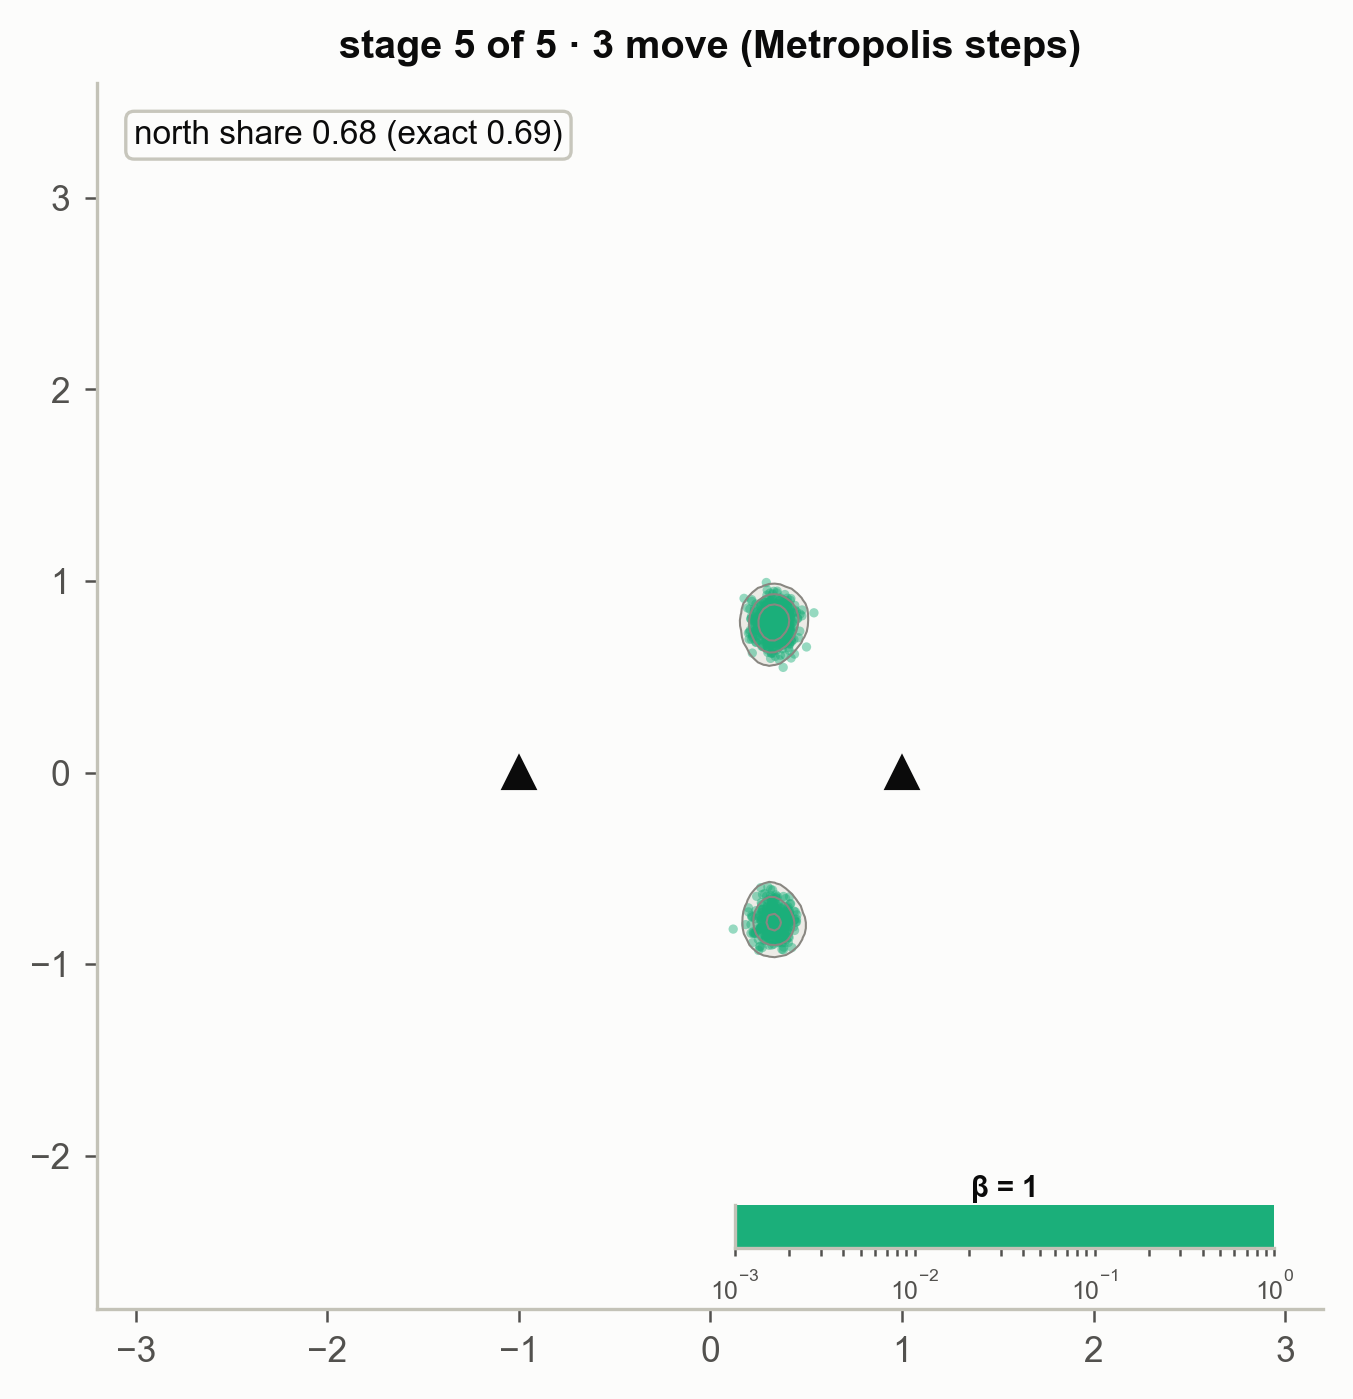

In [7]:
# the tempered posterior on a grid: log prior and log likelihood once, then p_beta = prior x L^beta for any beta
xg, yg = np.linspace(EXT[0], EXT[1], 220), np.linspace(EXT[2], EXT[3], 220)
GX, GY = np.meshgrid(xg, yg)
pts_g = np.column_stack([GX.ravel(), GY.ravel()])
LPRI = bim.logprior_batch(pts_g).reshape(GX.shape)
LLIK = bim.loglik_batch(pts_g).reshape(GX.shape)


def movie_frame(beta_bg, beta_bar, X, sizes, alphas, title, badge, save=None):
    global LAST_FRAME
    LAST_FRAME = (beta_bg, beta_bar, X, sizes, alphas, title, badge)
    fig, ax = plt.subplots(figsize=(5.0, 4.75), dpi=95)
    L = LPRI + beta_bg * LLIK
    Pm = np.exp(L - L.max())
    lev = sorted(set(P.hdr_levels(Pm).values()))
    ax.contourf(GX, GY, Pm, levels=lev + [Pm.max() * 1.01], colors=["#ecebe6", "#d9d8d1", "#c3c2b7"])
    ax.contour(GX, GY, Pm, levels=lev, colors=S.MUTED, linewidths=0.5)
    rgba = np.zeros((len(X), 4))
    rgba[:, :3] = matplotlib.colors.to_rgb(SMC_C)
    rgba[:, 3] = alphas
    ax.scatter(X[:, 0], X[:, 1], s=sizes, c=rgba, lw=0)
    ax.plot([-1, 1], [0, 0], "^", color=S.INK, ms=7)
    ax.set_xlim(EXT[0], EXT[1]); ax.set_ylim(EXT[2], EXT[3]); ax.set_aspect("equal")
    ax.set_title(title, fontsize=9.5)
    S.badge(ax, badge, loc="upper left", fs=8)
    bar = ax.inset_axes([0.52, 0.05, 0.44, 0.035])            # tempering progress, log scale
    bar.set_xscale("log"); bar.set_xlim(1e-3, 1); bar.set_ylim(0, 1)
    bar.axvspan(1e-3, max(beta_bar, 1.001e-3), color=SMC_C, lw=0)
    bar.set_yticks([]); bar.tick_params(labelsize=6, length=2)
    bar.set_title(f"β = {beta_bar:.3g}", fontsize=7, pad=2)
    fig.tight_layout()
    rgb = S.fig_to_rgb(fig)
    if save:
        bk.savefig(fig, save)
    plt.close(fig)
    return rgb


ease = lambda f: 0.5 - 0.5 * np.cos(np.pi * f)
S0 = 5.0                                                   # dot size of an ordinary particle
frames = []
X0 = steps[0]["X_before"]
for _ in range(8):                                         # the prior cloud, beta = 0
    frames.append(movie_frame(0.0, 0.0, X0, np.full(N, S0), np.full(N, 0.45), "start: N draws from the prior (β = 0)",
                              f"{N} particles"))
for k, st in enumerate(steps):
    b0, b1 = st["beta_from"], st["beta"]
    Xb, w, idx = st["X_before"], st["w"], st["idx"]
    cnt = np.bincount(idx, minlength=N)
    s_w = np.clip(w * N * S0, 0.3, 160)                    # dot area = weight
    s_c = np.clip(cnt * S0, 0.3, 160)                      # dot area = number of copies
    head = f"stage {k + 1} of {len(steps)}"
    for f in np.linspace(0, 1, 10):                        # 1. reweight: dot size follows the weight
        frames.append(movie_frame(b0, b0, Xb, S0 + ease(f) * (s_w - S0), np.full(N, 0.45),
                                  f"{head} · 1 reweight with L^Δβ (dot size = weight)", f"weight ESS {st['ess']:.0f} of {N}"))
    for f in np.linspace(0, 1, 8):                         # 2. resample: losers fade out, winners show their copies
        al = np.where(cnt > 0, 0.45, 0.45 * (1 - ease(f)))
        frames.append(movie_frame(b0, b0, Xb, s_w + ease(f) * (s_c - s_w), al,
                                  f"{head} · 2 resample (good particles cloned)", f"{np.sum(cnt > 0)} distinct particles survive"))
    start_pos = Xb[idx]                                    # every new particle starts on its parent
    for f in np.linspace(0, 1, 14):                        # 3. move: Metropolis steps, while beta reaches its new value
        e = ease(f)
        bg = np.exp(np.log(max(b0, 1e-4)) + e * (np.log(b1) - np.log(max(b0, 1e-4)))) if b0 > 0 else b1 * e
        frames.append(movie_frame(bg, b0 + e * (b1 - b0), start_pos + e * (st["X_moved"] - start_pos), np.full(N, S0),
                                  np.full(N, 0.45), f"{head} · 3 move (Metropolis steps)",
                                  f"north share {np.mean(st['X_moved'][:, 1] > 0):.2f} (exact {north_true:.2f})"))
    frames += [frames[-1]] * 4
gif = S.frames_to_gif(frames, S.FIG / "2-20_smc_bimodal.gif", fps=14, hold_last=20)
print("GIF size %.1f MB" % (gif.stat().st_size / 1e6))
S.show_gif(gif, width=480)
movie_frame(*LAST_FRAME, save="2-20_smc_bimodal_final")          # the last frame again, as a 300-dpi still
final_png = S.FIG / "2-20_smc_bimodal_final.png"
from IPython.display import Image as _Image, display as _display
print("The last frame at full resolution (300 dpi):")
_display(_Image(filename=str(final_png), width=480))

saved figures/2-20_smc_stages.png


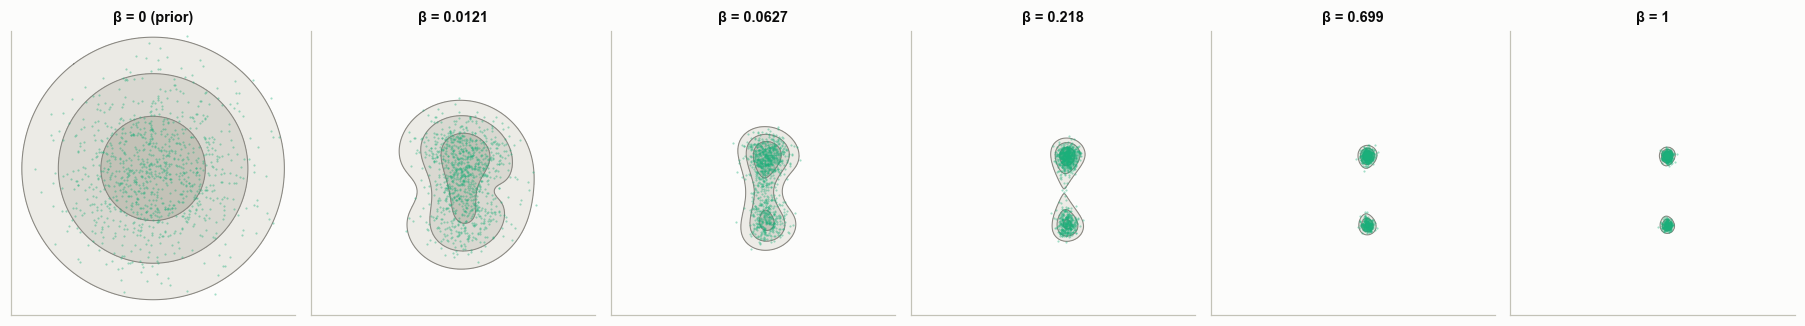

north share after the last stage: SMC 0.676, exact (grid) 0.686


In [8]:
fig, axs = plt.subplots(1, len(steps) + 1, figsize=(2.75 * (len(steps) + 1), 3.0))
BP.density(axs[0], P.grid(tempered(bim, 0.0), extent=EXT, n=250), fill=True)
axs[0].scatter(*steps[0]["X_before"].T, s=2, color=SMC_C, alpha=0.4, lw=0)
axs[0].set_title("β = 0 (prior)", fontsize=9.5)
for ax, st in zip(axs[1:], steps):
    BP.density(ax, P.grid(tempered(bim, st["beta"]), extent=EXT, n=250), fill=True)
    ax.scatter(*st["X_moved"].T, s=2, color=SMC_C, alpha=0.4, lw=0)
    ax.set_title(f"β = {st['beta']:.3g}", fontsize=9.5)
for ax in axs:
    ax.set_xlim(-3.2, 3.2); ax.set_ylim(-2.8, 3.6); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
bk.savefig(fig, "2-20_smc_stages")
plt.show()
print("north share after the last stage: SMC %.3f, exact (grid) %.3f" % (np.mean(steps[-1]["X_moved"][:, 1] > 0), north_true))

## 5. The adaptive schedule: how big is each step in β?

If β jumps too far in one stage, a few particles get almost all the weight and the population collapses
(section 8). If it creeps, the run wastes forward models. The CATMIP rule (Minson et al. 2013) picks
$\Delta\beta$ by bisection so that the **coefficient of variation of the weights** equals 1:

$$\mathrm{COV}(w) = \frac{\mathrm{sd}(w)}{\mathrm{mean}(w)} = 1 \quad\Longleftrightarrow\quad \mathrm{ESS} = \frac{(\sum w_i)^2}{\sum w_i^2} = \frac{N}{1 + \mathrm{COV}^2} = \frac{N}{2}.$$

So every stage throws away about half the information in the weights, never more. (BEAT's `calc_beta` uses the
same criterion.) The move step's scale follows the "a + bR" rule, $c = 1/9 + 8/9 \cdot R$, where $R$ is the last
acceptance rate: when moves are accepted often, the next proposals get bolder.

saved figures/2-20_smc_schedule.png


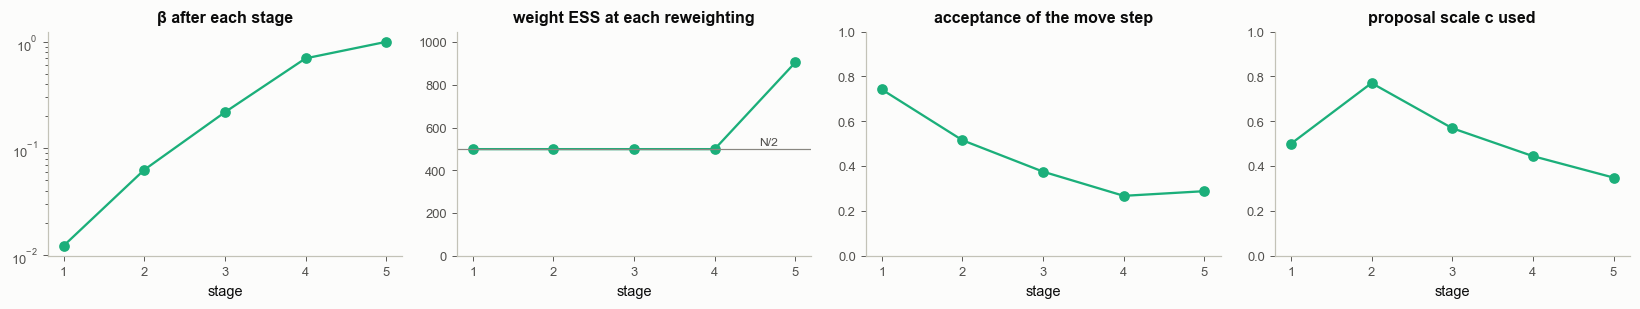

stage   beta      dbeta    weight ESS  acceptance  c
    1  0.01213  0.01213         500        0.74  0.50
    2  0.06274  0.05062         500        0.52  0.77
    3  0.21810  0.15536         500        0.38  0.57
    4  0.69932  0.48122         500        0.27  0.45
    5  1.00000  0.30068         906        0.29  0.35


In [9]:
k = np.arange(1, len(steps) + 1)
fig, axs = plt.subplots(1, 4, figsize=(15, 2.9))
axs[0].semilogy(k, [st["beta"] for st in steps], "o-", color=SMC_C, ms=6)
axs[0].set_title("β after each stage")
axs[1].plot(k, [st["ess"] for st in steps], "o-", color=SMC_C, ms=6)
axs[1].axhline(N / 2, color=S.MUTED, lw=0.8)
axs[1].text(4.55, N / 2 + 20, "N/2", color=S.INK2, fontsize=8)
axs[1].set_ylim(0, N * 1.05)
axs[1].set_title("weight ESS at each reweighting")
axs[2].plot(k, [st["accept"] for st in steps], "o-", color=SMC_C, ms=6)
axs[2].set_ylim(0, 1)
axs[2].set_title("acceptance of the move step")
axs[3].plot(k, [st["c"] for st in steps], "o-", color=SMC_C, ms=6)
axs[3].set_ylim(0, 1)
axs[3].set_title("proposal scale c used")
for ax in axs:
    ax.set_xlabel("stage")
    ax.set_xticks(k)
fig.tight_layout()
bk.savefig(fig, "2-20_smc_schedule")
plt.show()
print("stage   beta      dbeta    weight ESS  acceptance  c")
for i, st in enumerate(steps):
    print(f"{i + 1:5d}  {st['beta']:.5f}  {st['beta'] - st['beta_from']:.5f}  {st['ess']:10.0f}  {st['accept']:10.2f}  {st['c']:.2f}")

The β steps grow geometrically: early stages must be cautious because the prior is far from the posterior, later
stages can take big bites. The ESS sits at $N/2$ by construction (the last stage can be higher because it stops
at β = 1 before COV reaches 1). As the target sharpens, acceptance falls. The scale $c$ follows the acceptance of
the previous stage: it starts at 0.5, grows after the easy first stage, then shrinks as acceptance falls.

## 6. Two islands: SMC vs Metropolis and NUTS chains

Four Metropolis chains and four NUTS chains, started at four corners of the map (dispersed starts, as you should),
against one SMC run. Question: what fraction of the probability is in the northern island?

saved figures/2-20_two_islands_compare.png


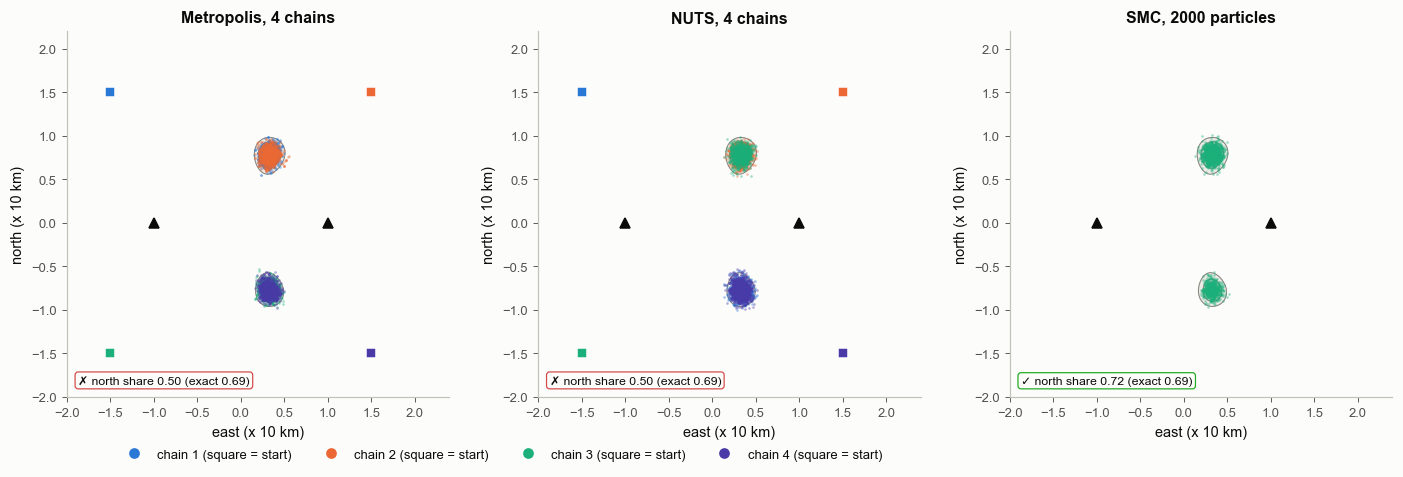

north share: Metropolis 0.500, NUTS 0.500, SMC 0.716, exact (grid) 0.686
R-hat of the north coordinate: Metropolis 1.74, NUTS 1.73
cost: Metropolis 24004 log-density evaluations, NUTS 22484 gradient evaluations, SMC 102000 log-density evaluations


SMC over 20 seeds: north share 0.689 ± 0.021 (sd), standard error of the mean 0.005


In [10]:
starts = np.array([[-1.5, 1.5], [1.5, 1.5], [-1.5, -1.5], [1.5, -1.5]])
bim.reset_counts()
rw = SM.rwm(bim, starts, 6000, step=0.05, rng=np.random.default_rng(0))
rw_cost = bim.n_logp
S_rw = rw["samples"][:, 1000:]
bim.reset_counts()
nu_ch = [SM.nuts(bim, starts[c], 1500, n_warmup=500, rng=np.random.default_rng(20 + c))["chain"] for c in range(4)]
nu_cost = bim.n_grad
S_nu = np.array(nu_ch)
sm = SM.smc(bim, n=2000, rng=np.random.default_rng(1))

fig, axs = plt.subplots(1, 3, figsize=(13, 4.1))
for ax, name in zip(axs, ["Metropolis, 4 chains", "NUTS, 4 chains", "SMC, 2000 particles"]):
    BP.density(ax, g_bim)
    ax.plot([-1, 1], [0, 0], "^", color=S.INK, ms=7)
    ax.set_title(name)
for c in range(4):
    BP.samples(axs[0], S_rw[c], S.CHAINS[c], n_max=1500, s=3, alpha=0.4)
    BP.samples(axs[1], S_nu[c], S.CHAINS[c], n_max=1500, s=3, alpha=0.4)
    for ax in axs[:2]:
        ax.plot(*starts[c], "s", color=S.CHAINS[c], ms=7, mec=S.SURFACE)
BP.samples(axs[2], sm["samples"], SMC_C, s=3, alpha=0.4)
est = [np.mean(S_rw[..., 1] > 0), np.mean(S_nu[..., 1] > 0), np.mean(sm["samples"][:, 1] > 0)]
for ax, e in zip(axs, est):
    S.badge(ax, "north share %.2f (exact %.2f)" % (e, north_true), ok=abs(e - north_true) < 0.05, loc="lower left", fs=8)
    BP.frame(ax, bim, equal=True)
fig.legend(handles=BP.legend_handles([(f"chain {c + 1} (square = start)", S.CHAINS[c], "dot") for c in range(4)]),
           loc="lower center", ncol=4, bbox_to_anchor=(0.36, -0.02))
fig.tight_layout(rect=(0, 0.06, 1, 1))
bk.savefig(fig, "2-20_two_islands_compare")
plt.show()
print("north share: Metropolis %.3f, NUTS %.3f, SMC %.3f, exact (grid) %.3f" % (*est, north_true))
print("R-hat of the north coordinate: Metropolis %.2f, NUTS %.2f" % (D.rhat(S_rw[..., 1]), D.rhat(S_nu[..., 1])))
print("cost: Metropolis %d log-density evaluations, NUTS %d gradient evaluations, SMC %d log-density evaluations"
      % (rw_cost, nu_cost, sm["n_logp"]))
reps = np.array([np.mean(SM.smc(bim, n=2000, rng=np.random.default_rng(100 + s))["samples"][:, 1] > 0) for s in range(20)])
print("SMC over 20 seeds: north share %.3f ± %.3f (sd), standard error of the mean %.3f"
      % (reps.mean(), reps.std(), reps.std() / np.sqrt(reps.size)))

Each MCMC chain stays on the island nearest its start, so both chain-based answers are set by *how many chains
started on each side*, not by the posterior. R-hat (printed) does flag the disagreement between chains, which is
its job (notebook 2.19); it does not tell you the right proportion. SMC decides the proportion while the islands
are still connected (small β) and then carries it to β = 1. The 20-seed replicate (printed) is the noise floor
of that estimate: compare the exact value with the mean ± its standard error, not with one run. SMC also spent more
evaluations here (printed), but longer chains would not help them: at β = 1 they essentially never cross
(section 2).

## 7. Does tempering also help on a single ridge? A test

Does tempering also help on a single ridge or a banana? Test it with one knob: compare SMC with a Metropolis
sampler that uses **the same idea for its proposals** (a covariance-shaped proposal) but **no tempering**. It is
given the exact posterior covariance, a small advantage, since SMC must estimate its covariance from the particles
(in practice Metropolis would take it from a pilot run). Isotropic Metropolis and NUTS are included for scale.
Every method gets about 50,000 evaluations. Ten seeds per method, budgets printed. Score: the largest error of the posterior mean
(in posterior standard deviations) and the ratio of the estimated to the exact variance along the long axis.

saved figures/2-20_tempering_on_unimodal.png


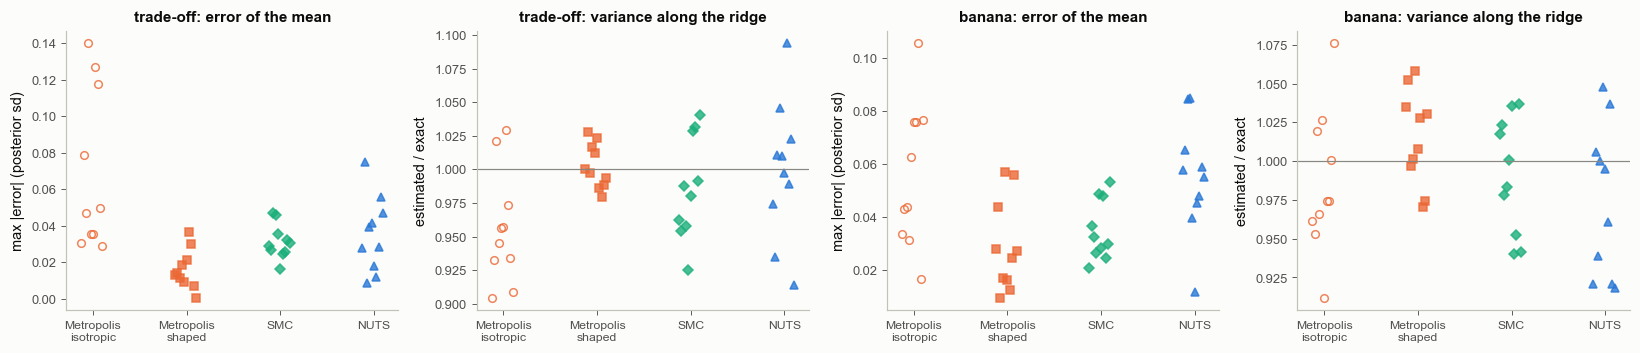


trade-off:  method                      budget   median mean-error  [range]        median variance ratio [range]
   Metropolis, isotropic          50004   0.048  [0.029, 0.140]   0.951  [0.90, 1.03]
   Metropolis, shaped             50004   0.014  [0.001, 0.037]   0.998  [0.98, 1.03]
   SMC (tempered, shaped)         51250   0.030  [0.016, 0.047]   0.984  [0.93, 1.04]
   NUTS                           50512   0.034  [0.009, 0.075]   1.004  [0.91, 1.09]

banana:  method                      budget   median mean-error  [range]        median variance ratio [range]
   Metropolis, isotropic          50004   0.053  [0.016, 0.106]   0.974  [0.91, 1.08]
   Metropolis, shaped             50004   0.026  [0.009, 0.057]   1.018  [0.97, 1.06]
   SMC (tempered, shaped)         49600   0.031  [0.021, 0.053]   0.992  [0.94, 1.04]
   NUTS                           49502   0.056  [0.012, 0.085]   0.978  [0.92, 1.05]

budget = log-density evaluations (Metropolis, SMC) or gradient evaluations (NUTS), sum

In [11]:
def scores(Xs, g, U, sd):
    m_err = np.abs((Xs.mean(0) - g.mean) @ U / sd).max()
    v_ratio = (U[:, 1] @ np.cov(Xs.T) @ U[:, 1]) / sd[1] ** 2
    return m_err, v_ratio


cmp_rows = {}
for pname, prob in [("trade-off", P.correlated()), ("banana", P.location(kind="banana"))]:
    g = P.grid(prob, n=500)
    ev, U = np.linalg.eigh(g.cov)
    sd = np.sqrt(ev)
    out = {k: [] for k in ["Metropolis, isotropic", "Metropolis, shaped", "SMC (tempered, shaped)", "NUTS"]}
    cost = {}
    n_smc = {"trade-off": 1250, "banana": 1600}[pname]          # chosen so SMC spends about 50,000 evaluations
    for seed in range(10):
        rng = np.random.default_rng(seed)
        x0 = prob.sample_prior(rng, 4)
        prob.reset_counts()
        r = SM.rwm(prob, x0, 12500, step=2.38 / np.sqrt(2) * sd[0], rng=rng)
        cost["Metropolis, isotropic"] = prob.n_logp
        out["Metropolis, isotropic"].append(scores(r["samples"][:, 2500:].reshape(-1, 2), g, U, sd))
        prob.reset_counts()
        r = SM.rwm(prob, x0, 12500, step=2.38 / np.sqrt(2), cov=g.cov, rng=rng)
        cost["Metropolis, shaped"] = prob.n_logp
        out["Metropolis, shaped"].append(scores(r["samples"][:, 2500:].reshape(-1, 2), g, U, sd))
        s = SM.smc(prob, n=n_smc, rng=rng)
        cost["SMC (tempered, shaped)"] = s["n_logp"]
        out["SMC (tempered, shaped)"].append(scores(s["samples"], g, U, sd))
        prob.reset_counts()
        ch = [SM.nuts(prob, x0[c], 1000, n_warmup=300, rng=np.random.default_rng(1000 * seed + c))["chain"] for c in range(4)]
        cost["NUTS"] = prob.n_grad
        out["NUTS"].append(scores(np.concatenate(ch), g, U, sd))
    cmp_rows[pname] = (out, cost)

cols = [S.COLORS["rwm"], S.COLORS["rwm"], SMC_C, S.COLORS["nuts"]]
mk = ["o", "s", "D", "^"]
fig, axs = plt.subplots(1, 4, figsize=(15, 3.3))
for j, pname in enumerate(cmp_rows):
    out, cost = cmp_rows[pname]
    for i, (name, vals) in enumerate(out.items()):
        v = np.array(vals)
        jit = (np.arange(len(v)) - len(v) / 2) * 0.025
        axs[2 * j].plot(i + jit, v[:, 0], mk[i], color=cols[i], ms=5, alpha=0.8, mfc=cols[i] if i != 0 else "none")
        axs[2 * j + 1].plot(i + jit, v[:, 1], mk[i], color=cols[i], ms=5, alpha=0.8, mfc=cols[i] if i != 0 else "none")
    axs[2 * j].set_title(f"{pname}: error of the mean", fontsize=10)
    axs[2 * j].set_ylabel("max |error| (posterior sd)")
    axs[2 * j + 1].set_title(f"{pname}: variance along the ridge", fontsize=10)
    axs[2 * j + 1].axhline(1.0, color=S.MUTED, lw=0.8)
    axs[2 * j + 1].set_ylabel("estimated / exact")
    for ax in axs[2 * j: 2 * j + 2]:
        ax.set_xticks(range(4))
        ax.set_xticklabels(["Metropolis\nisotropic", "Metropolis\nshaped", "SMC", "NUTS"], fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-20_tempering_on_unimodal")
plt.show()
for pname, (out, cost) in cmp_rows.items():
    print(f"\n{pname}:  method                      budget   median mean-error  [range]        median variance ratio [range]")
    for name, vals in out.items():
        v = np.array(vals)
        print(f"   {name:28s} {cost[name]:7d}   {np.median(v[:, 0]):.3f}  [{v[:, 0].min():.3f}, {v[:, 0].max():.3f}]   "
              f"{np.median(v[:, 1]):.3f}  [{v[:, 1].min():.2f}, {v[:, 1].max():.2f}]")
print("\nbudget = log-density evaluations (Metropolis, SMC) or gradient evaluations (NUTS), summed over chains")

Read the printed table, not only the dots. On one ridge or one banana, compare the two shaped methods: SMC and
the shaped Metropolis sampler use the same proposal shape, and the main difference is that SMC also tempers. If
tempering helped with these ridges, SMC would be clearly better at a similar budget. In this test it is not: the
shaped Metropolis sampler without tempering is at least as accurate on both problems, and the improvement of both
shaped methods over isotropic Metropolis comes from the **proposal shape**. (NUTS is there for scale; in two
dimensions it has no advantage, its strength is high dimension, notebook 2.18.)

Read this as a result about these two problems and these budgets, not as a rule. The comparison is not perfectly
one-knob: the Metropolis sampler was handed the exact covariance, and SMC also differs in resampling, adaptation and
how it spends its evaluations. Tempering and geometry-aware moves address partly different difficulties (separated
modes; long, thin or curved regions), and practical SMC combines them, as here, where its moves are
covariance-shaped. And tempering is not only for multiple modes: SMC also estimates the evidence (section 9) and can
take in data sequentially. When chains disagree, first look at why (2.19, section 5): separate islands point to
tempering; a slowly explored ridge points to a better parameterisation or a proposal or mass matrix shaped like the
posterior.

## 8. Too big a step in β: particle degeneracy

What if we skip the schedule and jump from prior to posterior in one stage (β: 0 → 1)? Every prior draw is
weighted by its full likelihood, and in a problem where the posterior is much narrower than the prior, almost all
draws land where the likelihood is negligible.

N = 100: weight ESS 2.43, distinct particles after resampling 4, after moves 88, north share 0.450
N = 2000: weight ESS 15.38, distinct particles after resampling 63, after moves 1754, north share 0.565


saved figures/2-20_degeneracy.png


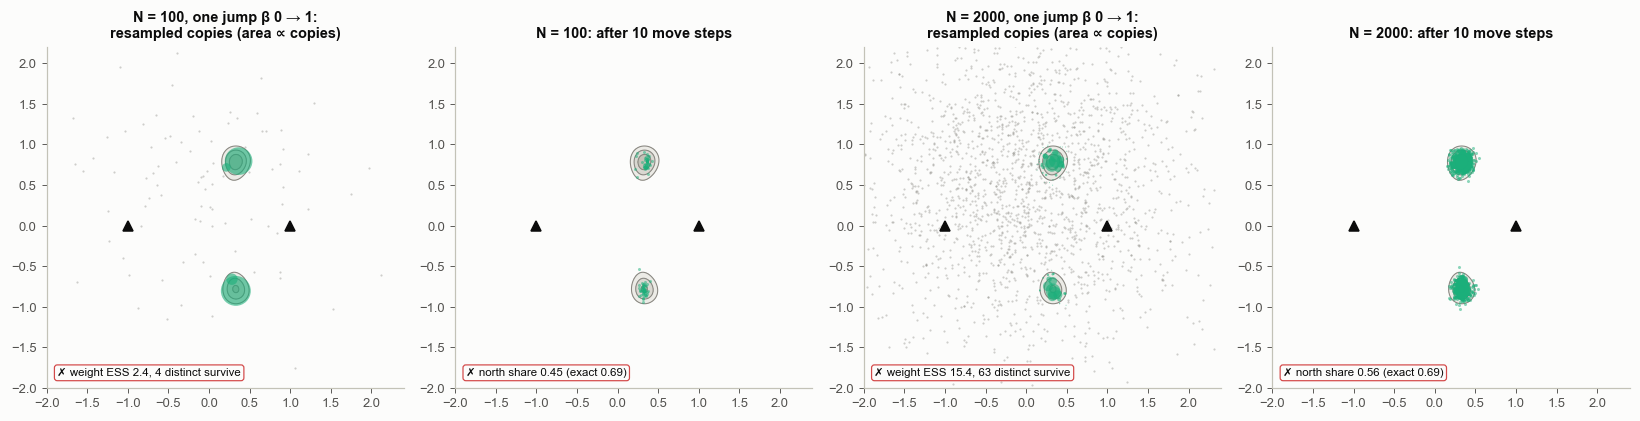

In [12]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.7))
for N_deg, ax_pair in [(100, axs[:2]), (2000, axs[2:])]:
    one = smc_steps(bim, N_deg, np.random.default_rng(1), betas=[1.0])[0]
    cnt = np.bincount(one["idx"], minlength=N_deg)
    keep = cnt > 0
    for ax in ax_pair:
        BP.density(ax, g_bim)
        ax.plot([-1, 1], [0, 0], "^", color=S.INK, ms=6)
        BP.frame(ax, bim, equal=True, labels=False)
    ax_pair[0].scatter(*one["X_before"][keep].T, s=cnt[keep] * 8 * 100 / N_deg, color=SMC_C, alpha=0.6, lw=0)
    ax_pair[0].scatter(*one["X_before"][~keep].T, s=2, color=S.MUTED, alpha=0.4, lw=0)
    ax_pair[0].set_title(f"N = {N_deg}, one jump β 0 → 1:\nresampled copies (area ∝ copies)", fontsize=9.5)
    S.badge(ax_pair[0], "weight ESS %.1f, %d distinct survive" % (one["ess"], keep.sum()), ok=False, loc="lower left", fs=7.5)
    ax_pair[1].scatter(*one["X_moved"].T, s=4, color=SMC_C, alpha=0.5, lw=0)
    ax_pair[1].set_title(f"N = {N_deg}: after 10 move steps", fontsize=9.5)
    share = np.mean(one["X_moved"][:, 1] > 0)
    S.badge(ax_pair[1], "north share %.2f (exact %.2f)" % (share, north_true), ok=abs(share - north_true) < 0.05,
            loc="lower left", fs=7.5)
    print(f"N = {N_deg}: weight ESS {one['ess']:.2f}, distinct particles after resampling {keep.sum()}, "
          f"after moves {len(np.unique(one['X_moved'].round(10), axis=0))}, north share {share:.3f}")
fig.tight_layout()
bk.savefig(fig, "2-20_degeneracy")
plt.show()

Grey dots in the left panel of each pair are the prior draws that got (almost) no weight; the aqua dots are the
few that survived, sized by their number of copies. The weight ESS printed above is a handful of particles out of
$N$: the whole population descends from those few ancestors, and the share of each island is decided by which
ancestors happened to land where. The move steps then spread the copies around those ancestors, so the cloud
*looks* healthy while its island proportions are wrong. More particles only postpone the problem here; a schedule
that keeps ESS ≈ N/2 at every stage removed it in this example. In general such a schedule limits the collapse of
the weights at each stage, but it cannot guarantee that every mode is found or that enough distinct ancestors
survive: a mode that no particle reaches while β is small cannot be weighted in later (and difficult multimodal
problems also depend on the path of intermediate distributions; Paulin et al. 2019).

**Two different ESS.** The weight ESS of this notebook, $(\sum w_i)^2/\sum w_i^2$, measures how evenly the weights
are spread at one stage. It is not the ESS of 2.16 and 2.19, which counts how many independent draws a correlated
chain is worth. After many resampling steps the particles can share few ancestors, so the final population can be
worth fewer independent draws than its weight ESS suggests; repeating the run with other seeds (section 6) is the
direct check.

## 9. A by-product: the evidence

Each reweighting step also estimates how much the average weight is, and the product over stages is the
**evidence** (marginal likelihood) $Z = \int p(\mathbf m) L(\mathbf m)\, d\mathbf m$, the quantity used to compare
models. Here it can be checked against a grid integral. Then the prior is widened while the data stay the same.

In [13]:
st_xy = np.array([[-1.0, 0.0], [1.0, 0.0]])


def bimodal_with_prior(sd):
    return P.InverseProblem(P._station_forward(st_xy), bim.y, bim.sigma, m0=[0.0, 0.5], P=np.eye(2) * sd ** 2,
                            extent=bim.extent)


def grid_logZ(prob, lim=8.0, n=900):
    x = np.linspace(-lim, lim, n)
    X, Y = np.meshgrid(x, x)
    pts = np.column_stack([X.ravel(), Y.ravel()])
    v = prob.loglik_batch(pts) + prob.logprior_batch(pts) - 0.5 * np.log(np.linalg.det(2 * np.pi * prob.P))
    return v.max() + np.log(np.sum(np.exp(v - v.max())) * (x[1] - x[0]) ** 2)


print("prior sd   log Z (SMC, 3 seeds)          log Z (grid)   median WRMS of posterior draws")
for sd_p in [0.5, 1.0, 2.0, 4.0]:
    prob = bimodal_with_prior(sd_p)
    runs = [SM.smc(prob, n=2000, rng=np.random.default_rng(s)) for s in range(3)]
    pred = prob.forward_batch(runs[0]["samples"])
    wrms = np.sqrt(np.mean(((prob.y - pred) / prob.sigma) ** 2, axis=1))
    print(f"{sd_p:8.1f}   {', '.join('%.3f' % r['logZ'] for r in runs):28s}  {grid_logZ(prob):10.3f}   {np.median(wrms):.3f}")

prior sd   log Z (SMC, 3 seeds)          log Z (grid)   median WRMS of posterior draws


     0.5   -4.539, -4.543, -4.576            -4.566   0.832


     1.0   -5.394, -5.338, -5.319            -5.329   0.816


     2.0   -6.408, -6.385, -6.368            -6.419   0.813


     4.0   -7.671, -7.734, -7.760            -7.718   0.845


The SMC estimate agrees with the grid integral, and the fit to the data (WRMS of the posterior draws) is the same
for every prior width. The evidence, however, drops as the prior widens: a wider prior spreads its probability over
more models that do not fit, and $Z$ averages the likelihood over the prior. That sensitivity to an often arbitrary
prior width is why many inversion reports quote fit measures (WRMS, χ² per data set) alongside or instead of the log
evidence, and why an evidence comparison between models needs priors chosen with as much care as the models (2.29).

## 10. Summary

| idea | picture | what goes wrong without it |
|---|---|---|
| tempering $p(\mathbf m)L^\beta$ | the sea between islands is shallow at small β | chains stay on the island where they started |
| reweight | particles that fit better count more | none: it is exact, but uneven weights waste particles |
| resample | weights become copies | weights would keep multiplying and degenerate |
| move | copies spread out under $p_\beta$, with covariance-shaped proposals | the population would be stuck at the ancestors' positions |
| COV = 1 rule | each stage keeps ESS ≈ N/2 | too big a step in β: degeneracy and wrong island shares (section 8) |

**In practice.** CATMIP (Minson et al. 2013) and its AlTar implementation, widely used for finite-fault inversion,
are this algorithm: β chosen so that the weights have COV = 1 (ESS = N/2; BEAT's `calc_beta` uses the same rule),
resampling, then Metropolis moves whose proposal covariance is the *weighted* particle covariance scaled by
$c = a + bR$. CATMIP adds "cascading", bringing data sets in one after another on top of the tempering schedule.
When an SMC run misbehaves, check the move step (section 3) and the weight ESS per stage (sections 5 and 8) before
the schedule.

Next: [**2.21 · Variational inference and normalizing flows (optional)**](2-21_variational_inference_flows.ipynb).